# Signed vertical orientation of S-net accelerometers

This notebook estimates the vertical axis from bottom pressure and three-component acceleration and assigns its polarity from the filtered signals. Set `DATA_ROOT` in the configuration cell, then run all cells. In Colab, optionally enable `MOUNT_GOOGLE_DRIVE`. The required Python packages are NumPy, SciPy, pandas and Matplotlib. CuPy is optional and should match the CUDA installation (for example, `cupy-cuda12x` for CUDA 12).

### Input and output

- Place the one-column pressure files in `DATA_ROOT/pressure/<event>/` and the three acceleration components in `DATA_ROOT/acceleration/<event>/`. The station table maps channel names to files and provides the calibration factors and water depths. Pressure is sampled at 10 Hz and acceleration at 100 Hz.
- The four input records must have a common time origin and continuous sampling. The one-column format has no timestamps for checking alignment. `DAT_HAS_HEADER` defaults to the original notebook's header handling.
- Each event produces a CSV with upward and downward angles, signed ratio statistics and processing status. The grid figure is saved as PNG and PDF. The red star marks the upward maximum whenever polarity is resolved.

### Method

The direction vector in sensor coordinates is
`u = (sin(η) cos(κ), sin(η) sin(κ), cos(η))`, with inclination η measured from sensor +Z and azimuth κ measured from sensor +X toward +Y. At a pole, azimuth is undefined and its reported value is a coordinate convention.

The axis maximizes the rectangular frequency-bin integral of Welch magnitude-squared coherence (MSC) between pressure and projected acceleration. The antipodal direction has the same MSC. The same zero-phase Butterworth bandpass is applied to pressure and to acceleration projected onto one candidate. With positive pressure polarity, the candidate with positive median `a_filtered / p_filtered` is assigned upward and the antipode downward. The CSV includes `fraction_positive_up`, the fraction of retained ratios that are positive for the chosen upward direction, as a sign-consistency diagnostic.

The default grid uses exact 1° steps and both stages use `f_g < f < min(f_ac, 0.1 Hz)`, where `f_g = 0.366 sqrt(9.8 / H)` and `f_ac = 1500 / (4 H)` for depth H in metres. Set `REPRODUCE_LEGACY_SCAN = True` to use the original linspace grid and `max(f_ac, 0.1 Hz)` for MSC. The sign filter always uses the capped forced-oscillation band. The original file calibration, FFT resampling length, detrending, and 17,500-sample skip are retained. By default the window ends at the last common sample. Set `WINDOW_SECONDS = 7200` to cap it at two hours.


## Configuration

In [6]:
from pathlib import Path
from dataclasses import dataclass
import math
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import fft, signal

DATA_ROOT = Path("/content/drive/MyDrive/data")
OUTPUT_DIR = Path("signed_vertical_results")
MOUNT_GOOGLE_DRIVE = True

# Available keys: Noto, Gulf, Kamchatka, Chignik.
EVENT_KEYS = ("Kamchatka","Sanriku")
STATION_IDS = None  # None uses all six stations.
BACKEND = "auto"  # "auto" tries CUDA/CuPy first; "cpu" uses NumPy/SciPy.
SHOW_FIGURES = True

DAT_HAS_HEADER = True
SKIP_SAMPLES = 17_500  # Samples at 10 Hz, after accelerometer resampling.
WINDOW_SECONDS = None
REPRODUCE_LEGACY_SCAN = False

FS = 10.0
NPERSEG = 2**13
BATCH_SIZE = 256
FILTER_ORDER = 4
PRESSURE_EPS = 1e-12  # Exclude denominators at or below this magnitude, in Pa.

EVENTS = {
    "Noto": "Noto, 2024",
    "Gulf": "Gulf of Alaska, 2018",
    "Kamchatka": "Kamchatka, 2025",
    "Chignik": "Chignik, 2021",
    "Sanriku": "Sanriku, 2026"
}


@dataclass(frozen=True)
class Station:
    name: str
    depth_m: float
    pressure: str
    acceleration_xyz: tuple
    sensitivity_xyz: tuple


STATIONS = (
    Station("S2N17", 2247, "e30e", ("e300", "e301", "e302"), (0.04792, 0.04923, 0.04893)),
    Station("S2N18", 2460, "e31e", ("e310", "e311", "e312"), (0.04930, 0.04885, 0.04878)),
    Station("S4N06", 1970, "e65c", ("e650", "e651", "e652"), (0.04863, 0.04856, 0.04874)),
    Station("S4N11", 2273, "e6ae", ("e6a0", "e6a1", "e6a2"), (0.04818, 0.04912, 0.04829)),
    Station("S4N25", 2228, "e78e", ("e780", "e781", "e782"), (0.04811, 0.04729, 0.04792)),
    Station("S6N08", 5900, "ea7e", ("ea70", "ea71", "ea72"), (0.05182, 0.05178, 0.05205)),
)


## Read and prepare the station records

In [2]:
def read_channel(path):
    frame = pd.read_csv(path, sep="\t", skip_blank_lines=False, header=0 if DAT_HAS_HEADER else None)
    if frame.shape[1] != 1 or frame.empty:
        raise ValueError(f"Expected one non-empty numeric column in {path}")
    data = frame.iloc[:, 0].to_numpy(dtype=np.float64)
    if not np.isfinite(data).all():
        raise ValueError(f"Non-finite samples in {path}")
    return data


def prepare_records(root, event, station):
    pressure_path = root / "pressure" / event / f"{station.pressure}.dat"
    acceleration_dir = root / "acceleration" / event
    pressure = read_channel(pressure_path) / 14.0
    components = []
    for code, sensitivity in zip(station.acceleration_xyz, station.sensitivity_xyz):
        raw = read_channel(acceleration_dir / f"{code}.dat")
        target_length = (raw.size + 1) // 10 - 1
        if target_length < 2:
            raise ValueError(f"Acceleration channel {code} is too short to resample")
        acceleration = signal.resample(raw / sensitivity * 4.377e-7, target_length)
        components.append(signal.detrend(acceleration))

    stop = min(pressure.size, *(component.size for component in components))
    if WINDOW_SECONDS is not None:
        stop = min(stop, SKIP_SAMPLES + round(WINDOW_SECONDS * FS))
    window = slice(SKIP_SAMPLES, stop)
    pressure = pressure[window]
    if pressure.size < NPERSEG + NPERSEG // 2:
        raise ValueError("Fewer than two complete Welch segments in the common window")
    if np.ptp(pressure) == 0:
        raise ValueError("Constant pressure in the common window")

    time_scaled = np.linspace(-1.0, 1.0, pressure.size)
    tide = np.polynomial.Polynomial.fit(time_scaled, pressure, deg=8)
    pressure = pressure - tide(time_scaled)
    acceleration = np.column_stack([component[window] for component in components])
    return pressure, acceleration


## Coherence scan and polarity

In [3]:
def choose_backend(mode):
    if mode == "cpu":
        return np, ()
    if mode != "auto":
        raise ValueError("BACKEND must be 'auto' or 'cpu'")
    try:
        import cupy as cp

        if cp.cuda.runtime.getDeviceCount() < 1:
            raise RuntimeError("no CUDA device visible")
        cp.empty(1)
    except (ImportError, OSError, RuntimeError, MemoryError) as exc:
        print(f"CUDA unavailable ({exc}). Using CPU.")
        return np, ()
    return cp, (RuntimeError, cp.cuda.memory.OutOfMemoryError)


def frequency_limits(depth_m):
    f_g = 0.366 * math.sqrt(9.8 / depth_m)
    f_ac = 1500.0 / (4.0 * depth_m)
    f_sign = min(f_ac, 0.1)
    f_scan = max(f_ac, 0.1) if REPRODUCE_LEGACY_SCAN else f_sign
    if not 0 < f_g < f_sign <= f_scan < FS / 2:
        raise ValueError(f"Invalid forced-oscillation band at depth {depth_m:g} m")
    return f_g, f_scan, f_sign


def unit_vectors(eta_deg, kappa_deg):
    eta, kappa = np.deg2rad(eta_deg), np.deg2rad(kappa_deg)
    sin_eta = np.where((eta_deg == 0) | (eta_deg == 180), 0.0, np.sin(eta))
    return np.stack((sin_eta * np.cos(kappa), sin_eta * np.sin(kappa), np.cos(eta)), axis=-1)


def make_grid():
    if REPRODUCE_LEGACY_SCAN:
        eta, kappa = np.linspace(0, 180, 180), np.linspace(0, 360, 360)
    else:
        eta, kappa = np.arange(181, dtype=float), np.arange(360, dtype=float)
    eta_mesh, kappa_mesh = np.meshgrid(eta, kappa, indexing="ij")
    return eta, kappa, unit_vectors(eta_mesh.ravel(), kappa_mesh.ravel())


def coherence_map(pressure, acceleration, directions, shape, f_low, f_high, xp):
    """Integrate Welch MSC over the requested band for each grid direction."""
    freqs = np.fft.rfftfreq(NPERSEG, d=1 / FS)
    bins = np.flatnonzero((freqs > f_low) & (freqs < f_high))
    if not bins.size:
        raise ValueError("No Welch frequency bins in the MSC integration band")

    records = xp.asarray(np.column_stack((pressure, acceleration)))
    segments = xp.stack([
        records[start:start + NPERSEG]
        for start in range(0, len(pressure) - NPERSEG + 1, NPERSEG // 2)
    ])
    segments -= segments.mean(axis=1, keepdims=True)
    segments *= xp.asarray(np.hanning(NPERSEG))[None, :, None]
    rfft = fft.rfft if xp is np else xp.fft.rfft
    spectra = rfft(segments, axis=1)[:, bins, :]
    p_fft, a_fft = spectra[..., 0], spectra[..., 1:]

    # Detrending, tapering and FFT are linear. Project the spectral terms
    # rather than computing a new FFT for every direction on the grid.
    power_p = xp.mean(xp.abs(p_fft)**2, axis=0)
    cross = xp.mean(p_fft.conj()[..., None] * a_fft, axis=0)
    power_xyz = xp.einsum("sfi,sfj->fij", a_fft.conj(), a_fft).real / len(segments)

    directions = xp.asarray(directions)
    values = xp.empty(len(directions))
    for start in range(0, len(directions), BATCH_SIZE):
        u = directions[start:start + BATCH_SIZE]
        cross_u = u @ cross.real.T + 1j * (u @ cross.imag.T)
        power_u = xp.einsum("bi,fij,bj->bf", u, power_xyz, u)
        denominator = power_u * power_p
        valid = denominator > 0
        msc = xp.where(valid, xp.abs(cross_u)**2 / xp.where(valid, denominator, 1), 0)
        values[start:start + len(u)] = xp.clip(msc, 0, 1).sum(axis=1) * (FS / NPERSEG)

    if xp is not np:
        values = xp.asnumpy(values)
    return values.reshape(shape)


def resolve_vertical(pressure, acceleration, eta, kappa, direction, f_low, f_high):
    """Orient the MSC axis by the median of the filtered acceleration/pressure ratio."""
    opposite_eta, opposite_kappa = 180.0 - eta, (kappa + 180.0) % 360.0
    sos = signal.butter(FILTER_ORDER, (f_low, f_high), fs=FS, btype="bandpass", output="sos")
    p_f, a_f = signal.sosfiltfilt(sos, np.column_stack((pressure, acceleration @ direction)), axis=0).T
    valid = np.isfinite(p_f) & np.isfinite(a_f) & (np.abs(p_f) > PRESSURE_EPS)
    ratios = a_f[valid] / p_f[valid]
    ratios = ratios[np.isfinite(ratios)]
    result = {"ratio_samples": ratios.size, "ratio_sample_fraction": ratios.size / pressure.size}
    median = float(np.median(ratios)) if ratios.size else 0.0
    if median == 0.0:
        return dict(result, status="unresolved_sign", detail="Median ratio is zero or undefined")

    if median < 0.0:
        eta, opposite_eta = opposite_eta, eta
        kappa, opposite_kappa = opposite_kappa, kappa
        ratios = -ratios

    # Projection onto the other candidate is exactly the negative of this one.
    mean_up = float(np.mean(ratios))
    return dict(
        result, status="ok", eta_up_deg=eta, kappa_up_deg=kappa,
        eta_down_deg=opposite_eta, kappa_down_deg=opposite_kappa,
        median_a_over_p_up=abs(median), median_a_over_p_down=-abs(median),
        mean_a_over_p_up=mean_up, mean_a_over_p_down=-mean_up,
        fraction_positive_up=float(np.mean(ratios > 0)),
    )


## Figures and result tables

In [13]:
def plot_event(event, stations, rows, maps, eta_grid, kappa_grid, output_dir):
    n_rows = min(3, len(stations))
    n_cols = math.ceil(len(stations) / n_rows)
    fig, axes = plt.subplots(
        n_rows, n_cols, squeeze=False, figsize=(5.4 * n_cols, 3.4 * n_rows),
        layout="constrained",
    )
    fig.suptitle(EVENTS[event])
    mesh = None
    for idx, ax in enumerate(axes.T.flat):
        if idx >= len(stations):
            ax.set_axis_off()
            continue
        station = stations[idx]
        row = rows[idx]
        ax.set_title(station.name)
        score = maps.get(station.name)
        if score is None:
            ax.text(0.5, 0.5, row["status"].replace("_", " "), ha="center", va="center",
                    transform=ax.transAxes)
            ax.set_axis_off()
            continue

        normalized = (score - score.min()) / (score.max() - score.min())
        kappa_plot = kappa_grid
        if kappa_grid[-1] < 360.0:
            kappa_plot = np.r_[kappa_grid, 360.0]
            normalized = np.column_stack((normalized, normalized[:, 0]))
        mesh = ax.pcolormesh(
            kappa_plot, eta_grid, normalized, shading="nearest",
            cmap="inferno", vmin=0, vmax=1, rasterized=True,
        )
        if row["status"] == "ok":
            ax.scatter(
                row["kappa_up_deg"], row["eta_up_deg"], marker="*", s=180,
                color="#ff2020", edgecolor="white", linewidth=0.8,
                zorder=5, clip_on=False,
            )
        else:
            ax.set_title(f"{station.name} (polarity unresolved)")

        ax.set(xlim=(0, 360), ylim=(0, 180), xticks=np.arange(0, 361, 60),
               yticks=np.arange(0, 181, 30), xlabel="κ (°)", ylabel="η (°)")
        ax.grid(color="white", linestyle=":", linewidth=0.5, alpha=0.45)

    if mesh is not None:
        fig.colorbar(mesh, ax=axes.ravel(), label="Normalized MSC integral", shrink=0.80)
        fig.supxlabel("Red star marks vertically upward", fontsize=10)
    for extension in ("png", "pdf"):
        fig.savefig(output_dir / f"{event}_coherence.{extension}", dpi=250)
    if SHOW_FIGURES:
        plt.show()
    plt.close(fig)


ANGLE_COLUMNS = ["eta_up_deg", "kappa_up_deg", "eta_down_deg", "kappa_down_deg"]
CSV_COLUMNS = [
    "event", "station", "status", *ANGLE_COLUMNS,
    "median_a_over_p_up", "median_a_over_p_down",
    "mean_a_over_p_up", "mean_a_over_p_down", "fraction_positive_up",
    "ratio_samples", "ratio_sample_fraction", "axis_eta_deg", "axis_kappa_deg",
    "msc_integral_peak_hz", "msc_mean_peak", "depth_m",
    "f_low_hz", "f_high_scan_hz", "f_high_sign_hz",
    "window_start_sample_10hz", "window_stop_sample_10hz", "n_samples",
    "welch_segments", "welch_nperseg", "sample_rate_hz", "filter_order",
    "legacy_scan", "backend", "detail",
]


def write_table(frame, path):
    frame.fillna("").to_csv(path, index=False, encoding="utf-8")


def run(data_root, output_dir, event_keys, station_ids=None):
    started = time.perf_counter()
    if not event_keys or len(set(event_keys)) != len(event_keys):
        raise ValueError("Choose one or more distinct event keys")
    if set(event_keys) - EVENTS.keys():
        raise ValueError(f"Available event keys: {', '.join(EVENTS)}")
    stations = [station for station in STATIONS if station_ids is None or station.name in station_ids]
    if not stations or (station_ids is not None and set(station_ids) - {st.name for st in stations}):
        raise ValueError("STATION_IDS must contain known station names")
    if SKIP_SAMPLES < 0 or (WINDOW_SECONDS is not None and WINDOW_SECONDS <= 0):
        raise ValueError("Use a nonnegative skip and positive window length")
    if not data_root.is_dir():
        raise FileNotFoundError(f"Set DATA_ROOT to the directory containing pressure/ and acceleration/: {data_root}")
    output_dir.mkdir(parents=True, exist_ok=True)
    eta_grid, kappa_grid, directions = make_grid()
    grid_shape = (len(eta_grid), len(kappa_grid))
    xp, gpu_errors = choose_backend(BACKEND)
    print(f"MSC backend: {'CPU' if xp is np else 'CUDA'}")

    frames = []
    for event in event_keys:
        rows, maps = [], {}
        for station in stations:
            row = {
                "event": event, "station": station.name, "depth_m": station.depth_m,
                "window_start_sample_10hz": SKIP_SAMPLES, "welch_nperseg": NPERSEG,
                "sample_rate_hz": FS, "filter_order": FILTER_ORDER, "legacy_scan": REPRODUCE_LEGACY_SCAN,
            }
            rows.append(row)
            try:
                f_low, f_scan, f_sign = frequency_limits(station.depth_m)
                row.update(f_low_hz=f_low, f_high_scan_hz=f_scan, f_high_sign_hz=f_sign)
                pressure, acceleration = prepare_records(data_root, event, station)
                row.update(n_samples=len(pressure), window_stop_sample_10hz=SKIP_SAMPLES + len(pressure),
                           welch_segments=1 + (len(pressure) - NPERSEG) // (NPERSEG // 2))
                msc_args = (pressure, acceleration, directions, grid_shape, f_low, f_scan)
                try:
                    score = coherence_map(*msc_args, xp=xp)
                except gpu_errors as exc:
                    print(f"CUDA failed for {event}/{station.name} ({exc}). Retrying on CPU.")
                    xp, gpu_errors = np, ()
                    score = coherence_map(*msc_args, xp=xp)
                row["backend"] = "cpu" if xp is np else "cuda"

                peak = float(score.max())
                if not np.isfinite(score).all() or peak <= 0 or np.ptp(score) <= 1e-10 * peak:
                    raise ValueError("The MSC map has no resolvable directional maximum")
                maps[station.name] = score
                index = int(np.argmax(score))
                i_eta, i_kappa = np.unravel_index(index, grid_shape)
                eta = float(eta_grid[i_eta])
                kappa = float(kappa_grid[i_kappa] % 360.0)
                freqs = np.fft.rfftfreq(NPERSEG, 1 / FS)
                bandwidth = np.count_nonzero((freqs > f_low) & (freqs < f_scan)) * FS / NPERSEG
                row.update(axis_eta_deg=eta, axis_kappa_deg=kappa, msc_integral_peak_hz=peak,
                           msc_mean_peak=peak / bandwidth)
                row.update(resolve_vertical(pressure, acceleration, eta, kappa, directions[index], f_low, f_sign))
            except FileNotFoundError as exc:
                row.update(status="missing_input", detail=str(exc))
            except (OSError, ValueError) as exc:
                row.update(status="invalid_input_or_axis", detail=str(exc))
            if row["status"] != "ok":
                print(f"{event}/{station.name}: {row['detail']}")

        frame = pd.DataFrame(rows, columns=CSV_COLUMNS)
        frames.append(frame)
        write_table(frame, output_dir / f"{event}_vertical_angles.csv")
        plot_event(event, stations, rows, maps, eta_grid, kappa_grid, output_dir)

    summary = pd.concat(frames, ignore_index=True)
    write_table(summary, output_dir / "vertical_angles.csv")
    displayed = ["event", "station", "status", *ANGLE_COLUMNS, "median_a_over_p_up", "fraction_positive_up"]
    formatters = dict.fromkeys(ANGLE_COLUMNS, "{:.3f}".format)
    formatters.update(median_a_over_p_up="{:.6e}".format, fraction_positive_up="{:.3f}".format)
    print(summary[displayed].to_string(index=False, na_rep="", formatters=formatters))
    print(f"Results saved to {output_dir.resolve()} ({time.perf_counter() - started:.2f} s)")
    return summary


## Run the analysis

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
MSC backend: CUDA


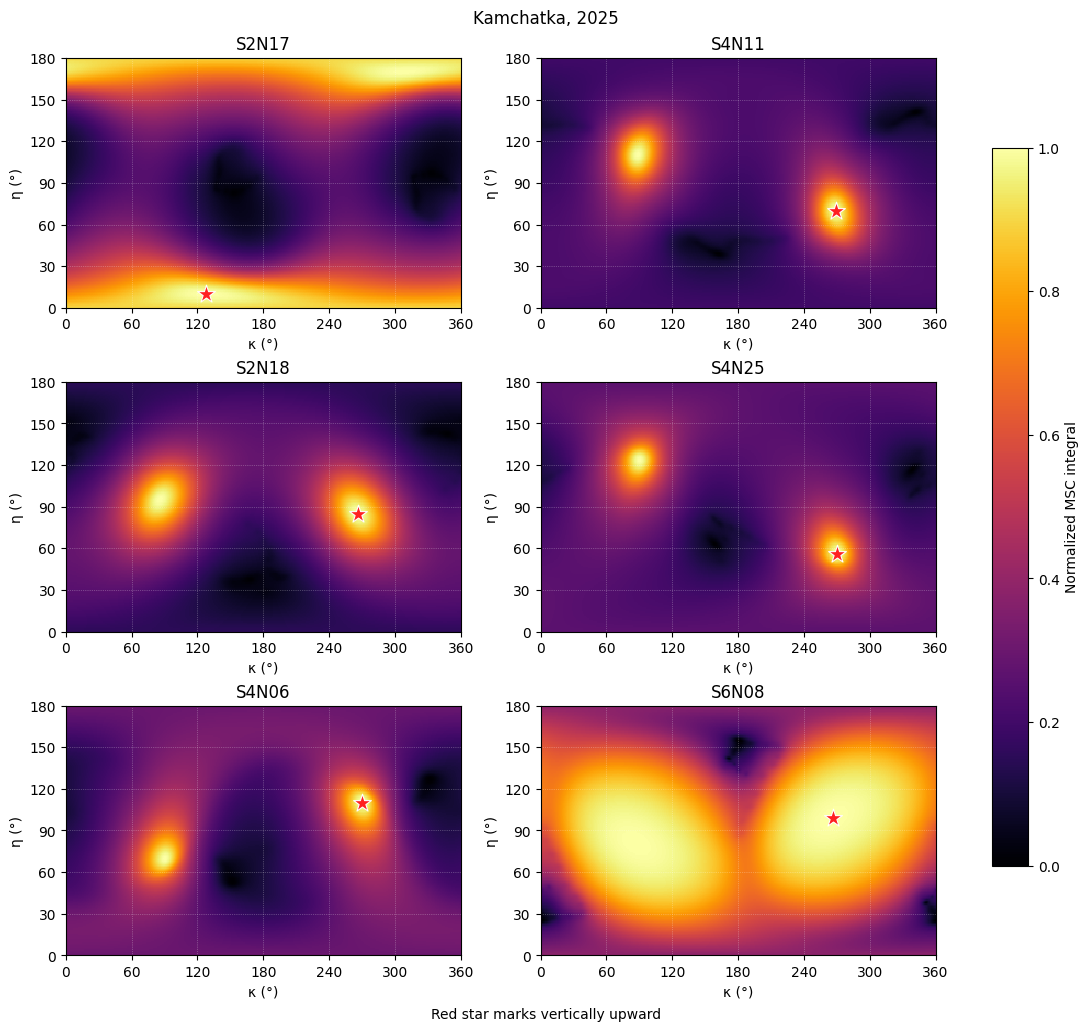

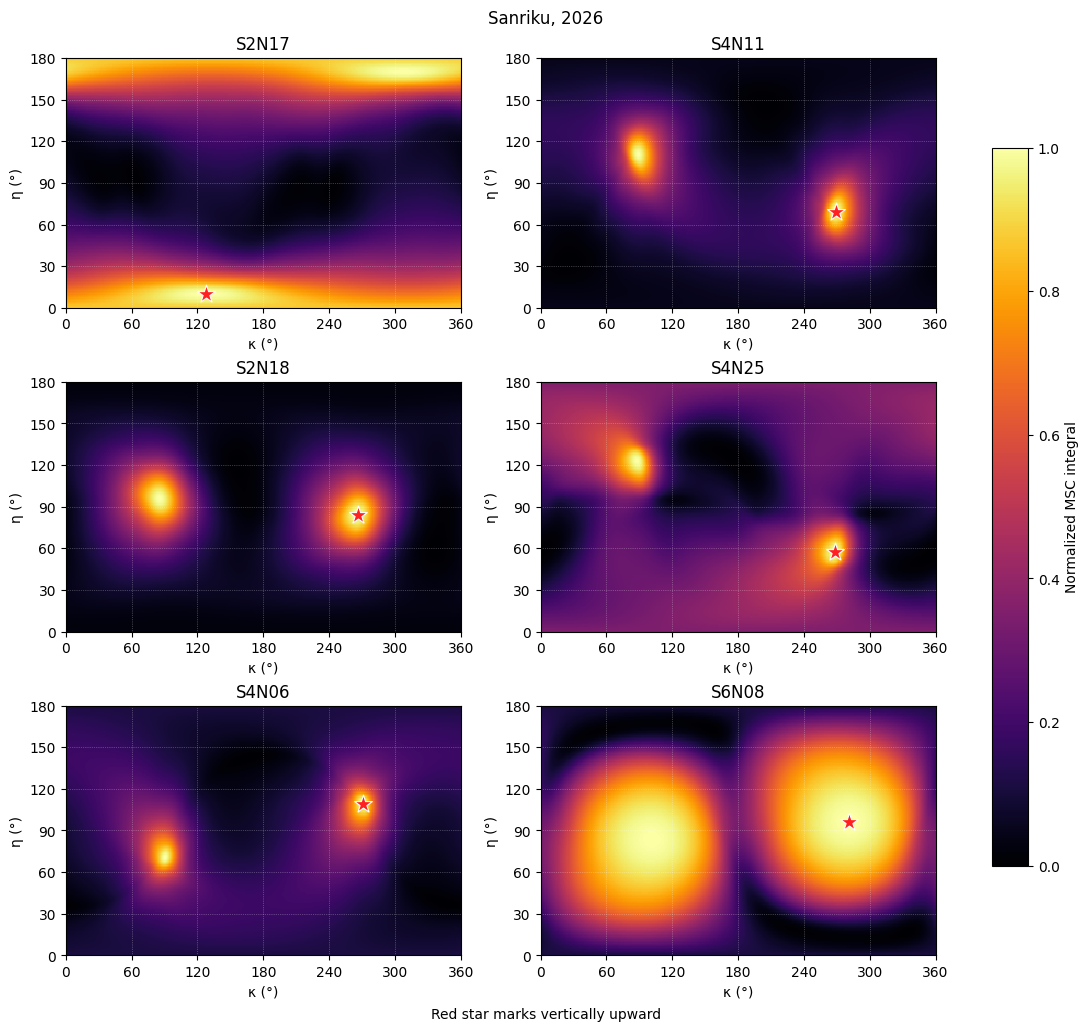

    event station status eta_up_deg kappa_up_deg eta_down_deg kappa_down_deg median_a_over_p_up fraction_positive_up
Kamchatka   S2N17     ok     10.000      128.000      170.000        308.000       4.385965e-07                0.846
Kamchatka   S2N18     ok     85.000      266.000       95.000         86.000       7.849608e-07                0.867
Kamchatka   S4N06     ok    110.000      270.000       70.000         90.000       4.917896e-07                0.841
Kamchatka   S4N11     ok     70.000      269.000      110.000         89.000       4.072543e-07                0.834
Kamchatka   S4N25     ok     56.000      270.000      124.000         90.000       4.768177e-07                0.856
Kamchatka   S6N08     ok     99.000      267.000       81.000         87.000       7.905310e-08                0.790
  Sanriku   S2N17     ok     10.000      128.000      170.000        308.000       1.478555e-07                0.694
  Sanriku   S2N18     ok     84.000      266.000       96.000   

In [14]:
if MOUNT_GOOGLE_DRIVE:
    from google.colab import drive

    drive.mount("/content/drive")

results = run(DATA_ROOT, OUTPUT_DIR, EVENT_KEYS, STATION_IDS)
